# Q1a

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Transpose so that rows are cells and columns are genes.
counts = pd.read_csv("pbmc_6Kcells_500genes.txt", sep="\t", index_col=0).T

library_sizes = counts.sum(axis=1)
median_library_size = library_sizes.median()
normalized = counts.div(library_sizes, axis=0) * median_library_size
log_expression = np.log1p(normalized)

print(f"{counts.shape[0]:,} cells and {counts.shape[1]} genes")
print(f"Median library size: {median_library_size:,.0f}")

6,825 cells and 500 genes
Median library size: 2,810


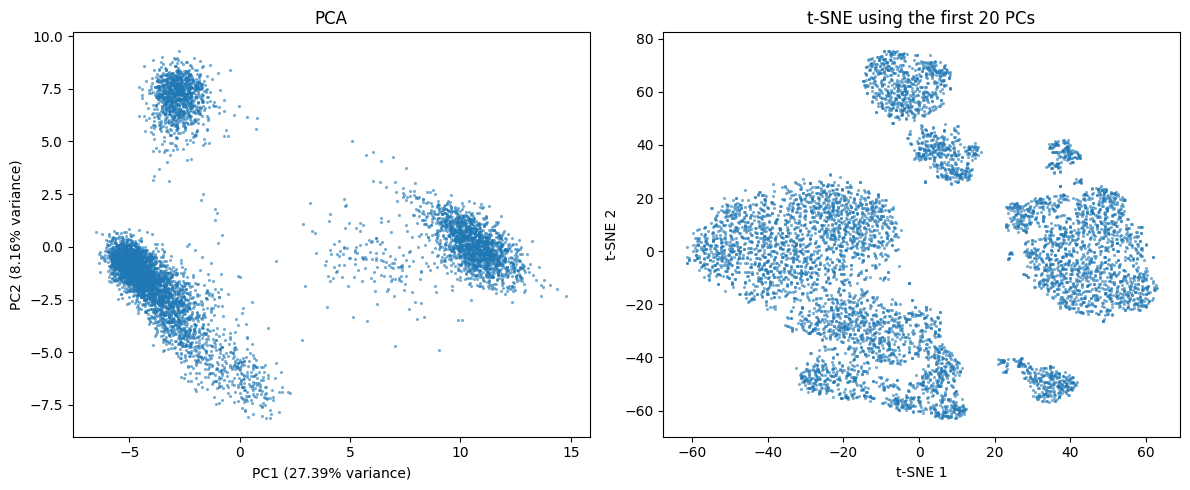

In [7]:
pca = PCA(svd_solver="full")
pc_scores = pca.fit_transform(log_expression)

embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42,
).fit_transform(pc_scores[:, :20])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(pc_scores[:, 0], pc_scores[:, 1], s=5, alpha=0.6, linewidths=0)
axes[0].set(
    title="PCA",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)",
)
axes[1].scatter(embedding[:, 0], embedding[:, 1], s=5, alpha=0.6, linewidths=0)
axes[1].set(title="t-SNE using the first 20 PCs", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

## Q1b

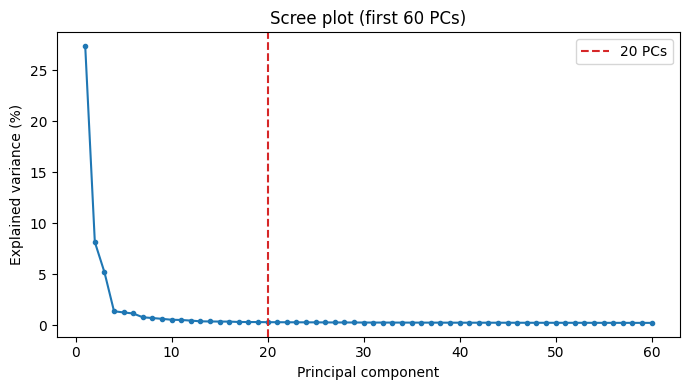

Variance explained by 20 PCs: 50.62%
Variance explained by PC 20: 0.28%


In [8]:
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, 61), 100 * variance_ratio[:60], marker="o", markersize=3)
plt.axvline(20, color="tab:red", linestyle="--", label="20 PCs")
plt.title("Scree plot (first 60 PCs)")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Variance explained by 20 PCs: {100 * variance_ratio[:20].sum():.2f}%")
print(f"Variance explained by PC 20: {100 * variance_ratio[19]:.2f}%")

20 PCs is a reasonable choice for an initial visualization, although it is not a clear optimal cutoff. The scree plot drops sharply over the first few PCs and then levels off, with no distinct elbow at 20. The first 20 PCs explain 50.62% of the variance, and PC 20 alone explains only 0.28%.

Using 20 PCs keeps the main patterns and may reduce noise, but it also leaves out about half of the total variance, which could include useful biological differences. Therefore, 20 is an ok choice but might not be the best.

## Q2

I applied K-means to the first 20 PCs and compared K = 2–10 using the silhouette score. A higher score indicates more compact and better-separated clusters. 

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = pc_scores[:, :20]
k_values = range(2, 11)
scores = []
models = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    score = silhouette_score(X, model.labels_)
    models.append(model)
    scores.append(score)
    print(f"K = {k}: silhouette score = {score:.3f}")

best_index = np.argmax(scores)
best_k = list(k_values)[best_index]
cluster_ids = models[best_index].labels_ + 1
print(f"\nSelected K = {best_k}")

K = 2: silhouette score = 0.511
K = 3: silhouette score = 0.472
K = 4: silhouette score = 0.493
K = 5: silhouette score = 0.446
K = 6: silhouette score = 0.374
K = 7: silhouette score = 0.264
K = 8: silhouette score = 0.226
K = 9: silhouette score = 0.229
K = 10: silhouette score = 0.218

Selected K = 2


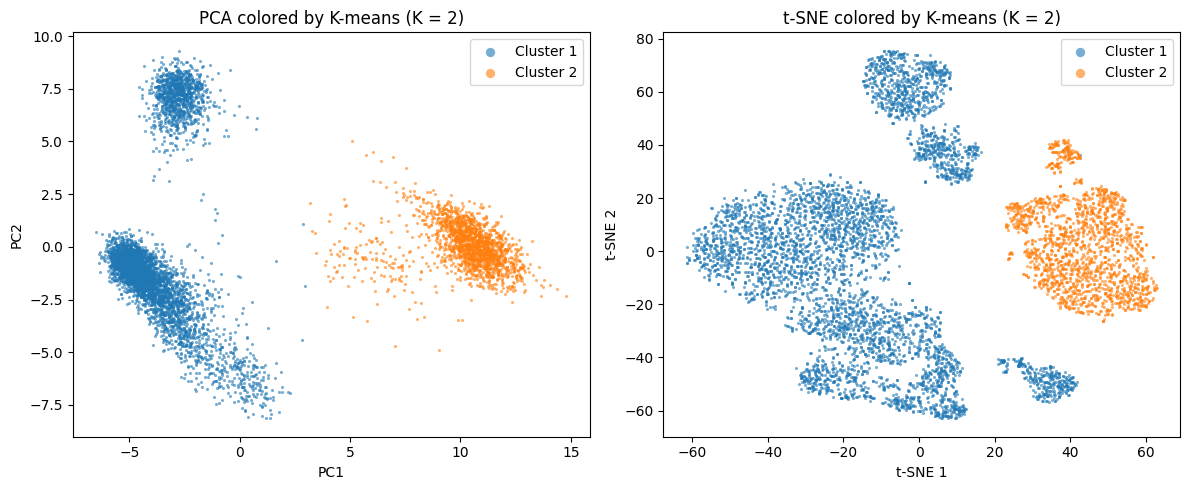

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = plt.get_cmap("tab10")

for cluster in range(1, best_k + 1):
    mask = cluster_ids == cluster
    axes[0].scatter(pc_scores[mask, 0], pc_scores[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")

axes[0].set(title=f"PCA colored by K-means (K = {best_k})",
            xlabel="PC1", ylabel="PC2")
axes[1].set(title=f"t-SNE colored by K-means (K = {best_k})",
            xlabel="t-SNE 1", ylabel="t-SNE 2")
for ax in axes:
    ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

I chose K = 2 because it had the highest silhouette score (0.511) among the values tested. This indicates that K = 2 produced the best-separated clusters among the tested values. The clustering was performed using the top 20 PCs for all 6,825 cells. Although the t-SNE plot shows more visually distinct groups, K-means assigns them to only two clusters because we chose K = 2, so these two clusters should not necessarily be interpreted as exactly two biological cell types.

## Q3

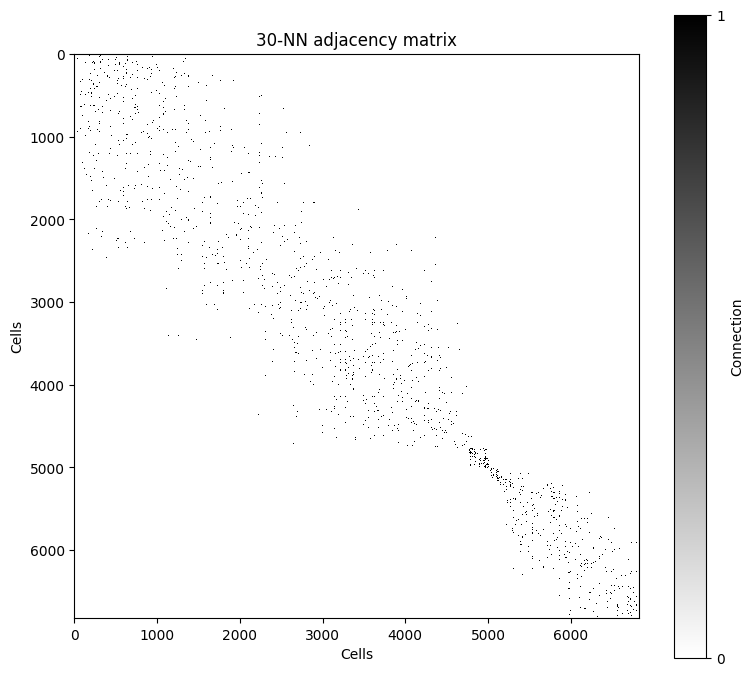

Adjacency matrix: 6,825 × 6,825
Directed edges: 204,750


In [11]:
from sklearn.neighbors import kneighbors_graph

adjacency = kneighbors_graph(
    pc_scores[:, :20],
    n_neighbors=30,
    mode="connectivity",
    metric="euclidean",
    include_self=False,
)

order = np.argsort(pc_scores[:, 0])
adjacency_plot = adjacency[order][:, order].astype(np.uint8).toarray()

fig, ax = plt.subplots(figsize=(8, 7))
heatmap = ax.imshow(adjacency_plot, cmap="binary", vmin=0, vmax=1,
                    interpolation="nearest")
ax.set(title="30-NN adjacency matrix", xlabel="Cells",
       ylabel="Cells")
fig.colorbar(heatmap, ax=ax, ticks=[0, 1], label="Connection")
plt.tight_layout()
plt.show()

print(f"Adjacency matrix: {adjacency.shape[0]:,} × {adjacency.shape[1]:,}")
print(f"Directed edges: {adjacency.nnz:,}")

Euclidean distance is appropriate because nearby cells in PCA space have similar patterns of normalized, log-transformed gene expression. It provides a direct measure of how close cells are based on their positions across the top 20 principal components. Since PCA captures the major sources of variation in the gene-expression data, this allows the nearest-neighbor graph to capture similarities between cells based on the main patterns of variation.

# Q4

In [7]:
import networkx as nx

undirected_adjacency = adjacency.maximum(adjacency.T)
graph = nx.from_scipy_sparse_array(undirected_adjacency)
communities = nx.community.louvain_communities(graph, resolution=1, seed=42)

louvain_ids = np.zeros(len(counts), dtype=int)
for cluster, cells in enumerate(communities, start=1):
    louvain_ids[list(cells)] = cluster

n_louvain = len(communities)
print(f"Louvain clusters: {n_louvain}")
print(f"K-means clusters: {best_k}")

Louvain clusters: 10
K-means clusters: 2


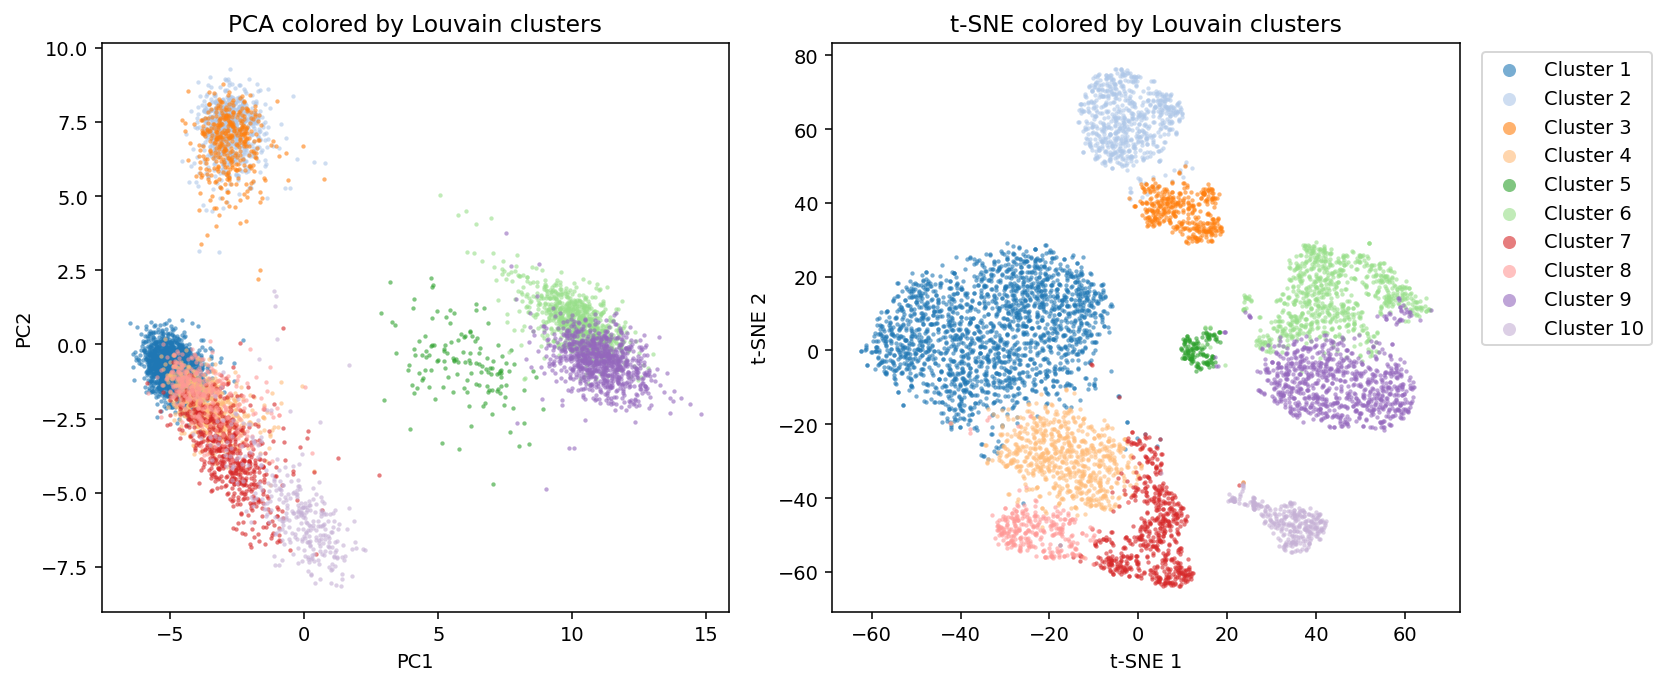

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = plt.get_cmap("tab20")

for cluster in range(1, n_louvain + 1):
    mask = louvain_ids == cluster
    axes[0].scatter(pc_scores[mask, 0], pc_scores[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1],
                    s=5, alpha=0.6, linewidths=0,
                    color=colors(cluster - 1), label=f"Cluster {cluster}")

axes[0].set(title="PCA colored by Louvain clusters", xlabel="PC1", ylabel="PC2")
axes[1].set(title="t-SNE colored by Louvain clusters", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=3)
plt.tight_layout()
plt.show()

Louvain found 10 clusters (does not require choosing the number of clusters in advance), compared with 2 from K-means. It mostly divides the two broad K-means clusters into smaller groups that match the local groups visible in the t-SNE plot. Some of these clusters overlap in the first two PCs because clustering uses information from all 20 PCs. K-means groups cells by their distances to cluster centers, while Louvain uses connections between neighboring cells. Marker-gene analysis is still needed to determine whether these clusters actually represent different cell types.